# 04 — Price Prediction Model

Reproduces the evaluation recorded in `reports/model_report.md`. Model training
is executed by `python -m src.modelling` (see `make model`); this notebook reads
the saved artefacts, inspects error behaviour and demonstrates inference.

**Target:** advertised nightly price in USD, trained on `log1p` and reported
after the inverse transform. The model is a price *estimator*, not a revenue,
occupancy or profit forecast.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

comparison = pd.read_csv("../outputs/tables/model_comparison.csv")
metadata = json.loads(Path("../outputs/models/model_metadata.json").read_text())
print("Best model:", metadata["model_family"])
print("FX assumption:", metadata["currency_assumption"])
comparison.sort_values("MAE_usd")

Best model: hist_gradient_boosting
FX assumption: ECB reference rates snapshot 2026-11-11


,model,n,MAE_usd,RMSE_usd,MedAE_usd,R2,MAPE_pct,median_abs_pct_error,train_MAE_usd,train_R2,MAE_gap_pct,fit_seconds
5,hist_gb_extended_features,55370,30.870992,66.436457,13.995163,0.600022,34.201699,24.906196,30.153856,0.634572,2.378254,NaN
0,random_forest,55370,31.621399,69.241674,13.989904,0.565531,34.518215,25.023315,27.519017,0.660017,14.907445,195.0
1,hist_gradient_boosting,55370,31.754802,67.986477,14.455112,0.581140,35.221765,25.971559,31.061422,0.618923,2.232287,23.5
2,ridge_regression,55370,39.756168,93.621214,19.076299,0.205723,46.914359,33.518088,40.095778,0.065744,-0.846995,13.2
3,baseline_city_median,55370,50.811943,103.068623,24.479400,0.037332,60.451318,44.444444,NaN,NaN,NaN,NaN
4,baseline_global_median,55370,59.669586,108.401495,36.126053,-0.064864,202.658350,51.334000,NaN,NaN,NaN,NaN


## Baseline comparison

The per-city median is the honest baseline: it already accounts for market level.
A model earns its place only if it improves on that.

In [2]:
comparison.set_index("model")[["MAE_usd", "RMSE_usd", "R2", "MedAE_usd", "median_abs_pct_error"]].round(3)

,MAE_usd,RMSE_usd,R2,MedAE_usd,median_abs_pct_error
model,,,,,
random_forest,31.621,69.242,0.566,13.990,25.023
hist_gradient_boosting,31.755,67.986,0.581,14.455,25.972
ridge_regression,39.756,93.621,0.206,19.076,33.518
baseline_city_median,50.812,103.069,0.037,24.479,44.444
baseline_global_median,59.670,108.401,-0.065,36.126,51.334
hist_gb_extended_features,30.871,66.436,0.600,13.995,24.906


## Cross-validation

In [3]:
pd.read_csv("../outputs/tables/model_cross_validation.csv")

,model,cv_folds,cv_MAE_log_usd_mean,cv_MAE_log_usd_std
0,ridge_regression,3,0.409389,0.000833
1,hist_gradient_boosting,3,0.325191,0.000935


## Where the model works and where it fails

In [4]:
display(pd.read_csv("../outputs/tables/model_error_by_city.csv"))
display(pd.read_csv("../outputs/tables/model_error_by_price_band.csv"))

,city,n,median_residual,mean_abs_error,median_abs_pct_error,p90_abs_pct_error
0,Bangkok,3833,-1.632356,19.313106,30.382380,77.135618
1,Cape Town,3779,-2.035041,42.752462,27.430899,75.513573
2,Hong Kong,1403,-0.956341,30.839054,24.439707,76.057631
3,Istanbul,4854,-0.265242,3.173934,32.998477,87.965298
4,Mexico City,3972,-1.235590,18.229380,26.609603,72.319456
5,New York,7324,-1.958739,39.176309,23.384888,62.331504
6,Paris,12804,-0.847250,32.233797,21.927274,59.631850
7,Rio de Janeiro,5268,-1.804262,39.950365,32.478596,92.597678
8,Rome,5474,-2.482584,33.768292,26.683847,72.106754
9,Sydney,6659,-2.371116,44.547104,26.131848,71.644405


,price_band,n,mae,median_ape
0,Q1 cheapest,11074,7.396361,36.290303
1,Q2,11094,14.716566,26.544836
2,Q3,11116,18.286916,20.354366
3,Q4,11019,26.140840,20.978863
4,Q5 dearest,11067,92.325583,30.299405


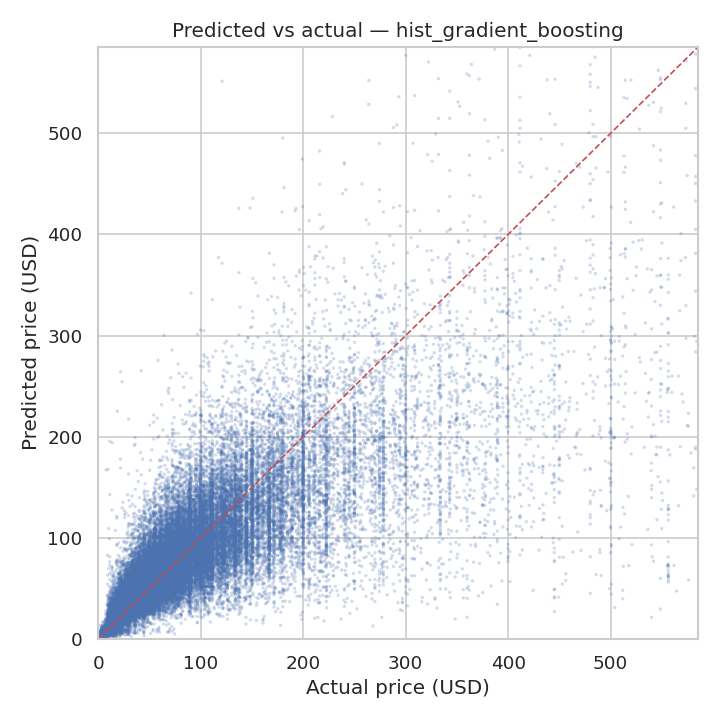

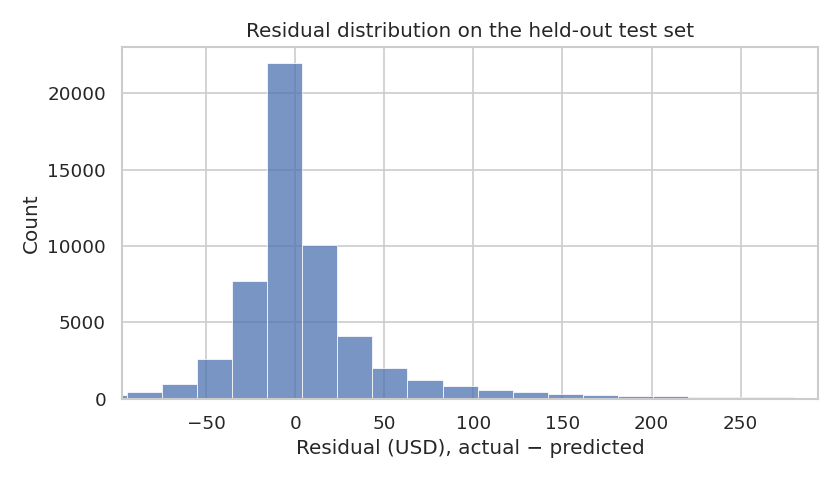

In [5]:
display(Image("../outputs/figures/ml_predicted_vs_actual.png"))
display(Image("../outputs/figures/ml_residuals.png"))

Residuals are wider at the top of the price range: expensive and unusual
properties are genuinely harder to price from the available attributes. The
largest individual errors are listed in
`outputs/tables/model_largest_errors.csv`.

## Feature importance

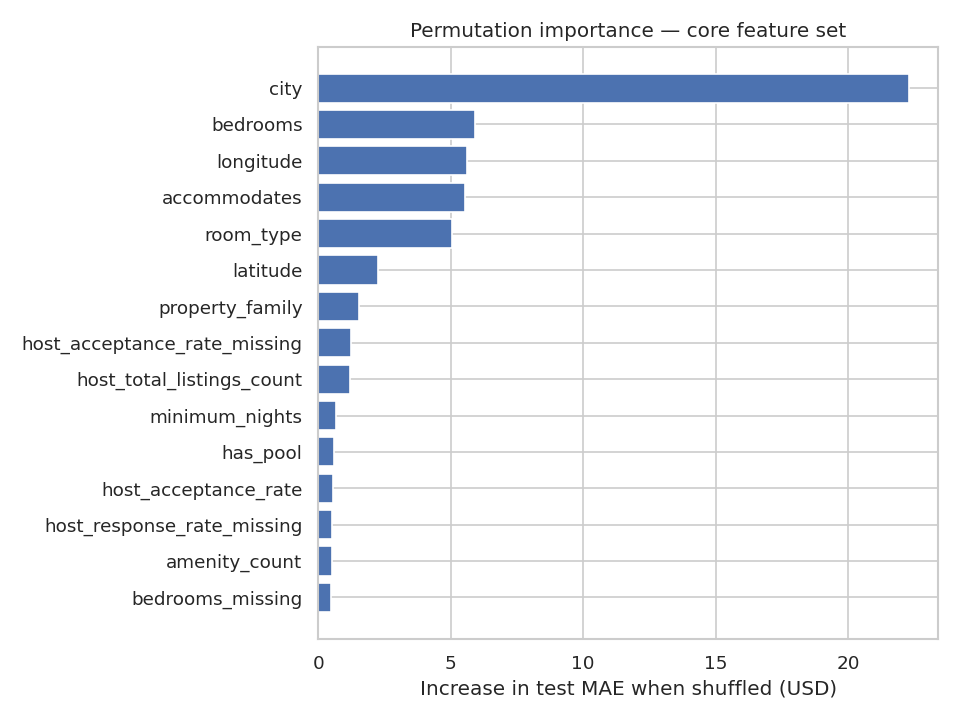

,feature,importance_mae_usd,std
0,city,22.303546,0.426653
1,bedrooms,5.922981,0.222141
2,longitude,5.629829,0.288476
3,accommodates,5.551113,0.347329
4,room_type,5.043231,0.248323
5,latitude,2.239029,0.042689
6,property_family,1.519096,0.103655
7,host_acceptance_rate_missing,1.212936,0.106391
8,host_total_listings_count,1.175503,0.157714
9,minimum_nights,0.677854,0.064535


In [6]:
display(Image("../outputs/figures/ml_feature_importance.png"))
importance = pd.read_csv("../outputs/tables/feature_importance_permutation.csv")
importance.head(15)

Permutation importance measures predictive contribution, not causal effect.
Location and capacity dominate, consistent with the statistical tests.

## Inference demonstration

In [7]:
from src.inference import predict_price

listing = {
    "city": "Rome",
    "room_type": "Entire place",
    "property_family": "apartment",
    "accommodates": 4,
    "bedrooms": 2,
    "minimum_nights": 2,
    "maximum_nights": 365,
    "amenity_count": 20,
    "latitude": 41.9028,
    "longitude": 12.4964,
    "host_total_listings_count": 3,
    "host_tenure_years": 6,
    "host_response_rate": 0.98,
    "host_acceptance_rate": 0.9,
    "host_response_time_rank": 1,
    "host_is_superhost": 1,
    "host_has_profile_pic": 1,
    "host_identity_verified": 1,
    "instant_bookable": 1,
}
predict_price(listing)

{'predicted_price_usd': 70.88,
 'predicted_price_local': 63.7,
 'local_currency': 'EUR',
 'basis': 'advertised nightly price (not revenue, occupancy or profit)',
 'model_family': 'hist_gradient_boosting',
 'currency_assumption': 'ECB reference rates snapshot 2026-11-11'}

## Limitations

- Predicted advertised price is not realised revenue.
- USD conversion depends on one ECB snapshot; local-currency outputs inherit that assumption.
- Extreme advertised prices were excluded from training; the model is conservative at the top of the market.
- CORE features exclude review history so the model works for a new listing.
- No bathrooms field exists; bedrooms is missing for ~10% of rows and is imputed.
- Feature importance is predictive, not causal.